In [13]:
#constants and imports

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t, binom


nu = 5
mu = 1
sigma = 0.01
n = 700

p = 0.975
q = 0.95

# Problem A.1 – Confidence Intervals for Quantiles

## (a) Constructing a 95% Exact Confidence Interval

## (b) Simulation of 200 Confidence Intervals

confidence interval: 1.02473051640241 1.0330980114810961
True quantile: 1.0257058183563632
Intervals containing the true quantile: 193/200
Empirical coverage: 96.500%


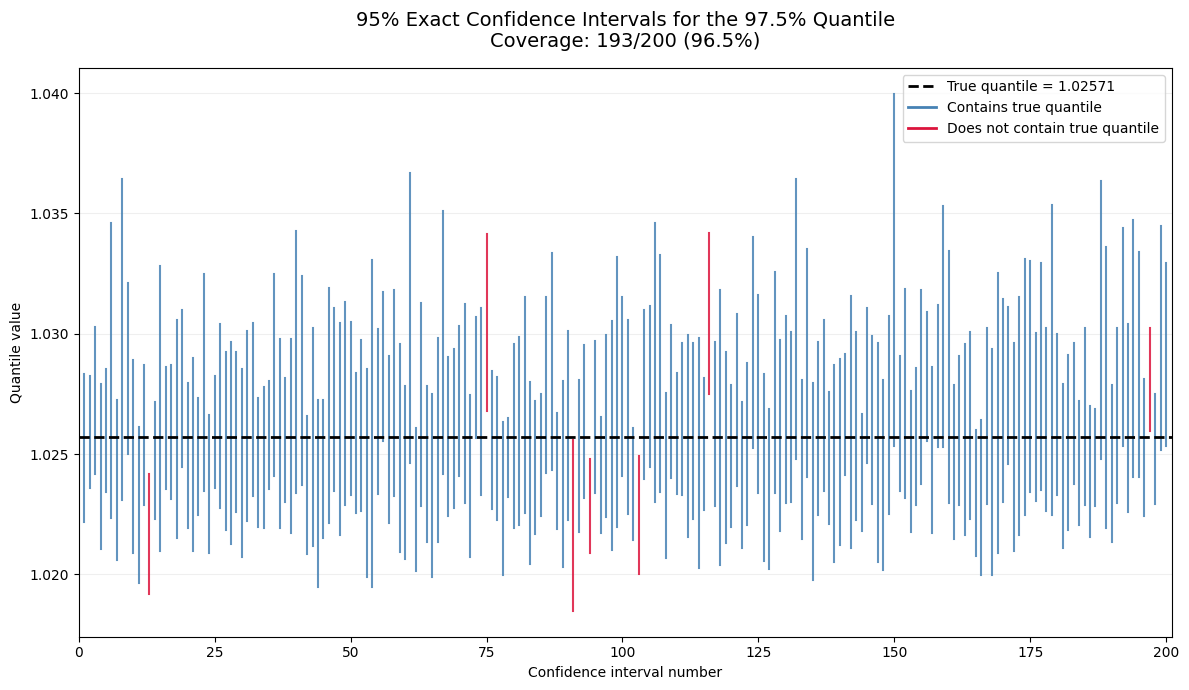

In [37]:

#t-distribution

np.random.seed(37)

theta_true = t.ppf(p, df=nu, loc=mu, scale=sigma)


def confint(k):
    x_lower_list = []
    x_upper_list = []
    for i in range(k):
        x_samples = t.rvs(df=nu, loc=mu, scale=sigma, size=n)
        x_sorted = np.sort(x_samples)

        #Find the smallest index y where P(Y>y) > a
        j1 = n - int(binom.ppf( (1+q)/2, n, 1-p ))
        j2 = n - int(binom.ppf( (1-q)/2, n, 1-p ))

        x_lower_list.append(x_sorted[j1-1])
        x_upper_list.append(x_sorted[j2-1])

        
    return x_lower_list, x_upper_list

#question A1(a)
x_lower_a, x_upper_a = confint(1)
x_lower_a = float(x_lower_a[0])
x_upper_a = float(x_upper_a[0])
print("confidence interval:", x_lower_a, x_upper_a)

k = 200
x_lower_b, x_upper_b = confint(k)
x_lower_b = np.array(x_lower_b)
x_upper_b = np.array(x_upper_b)

contains = (x_lower_b <= theta_true) & (theta_true <= x_upper_b)
count = 0
for c in contains:
    if c == True:
        count += 1
    else:
        pass

print(f"True quantile: {theta_true}")
print(f"Intervals containing the true quantile: {count}/{k}")
print(f"Empirical coverage: {count/k:.3%}")

fig, ax = plt.subplots(figsize=(12, 7))

for i in range(k):
    color = "steelblue" if contains[i] else "crimson"

    ax.plot(
        [i+1, i+1],
        [x_lower_b[i], x_upper_b[i]],
        color=color,
        linewidth=1.5,
        alpha=0.85
    )

# True quantile reference line
ax.axhline(theta_true, color="black", linestyle="--",
           linewidth=2, label=f"True quantile = {theta_true:.5f}")

# Legend
ax.plot([], [], color="steelblue", linewidth=2,
        label="Contains true quantile")
ax.plot([], [], color="crimson", linewidth=2,
        label="Does not contain true quantile")

ax.set_xlabel("Confidence interval number")
ax.set_ylabel("Quantile value")
ax.set_title(
    f"95% Exact Confidence Intervals for the 97.5% Quantile\n"
    f"Coverage: {count}/{k} ({count/k:.1%})",
    fontsize=14,
    pad=15
)

ax.set_xlim(0, k+1)
ax.grid(axis="y", alpha=0.2)
ax.legend(loc="best")

plt.tight_layout()
plt.show()


# Problem A.2 


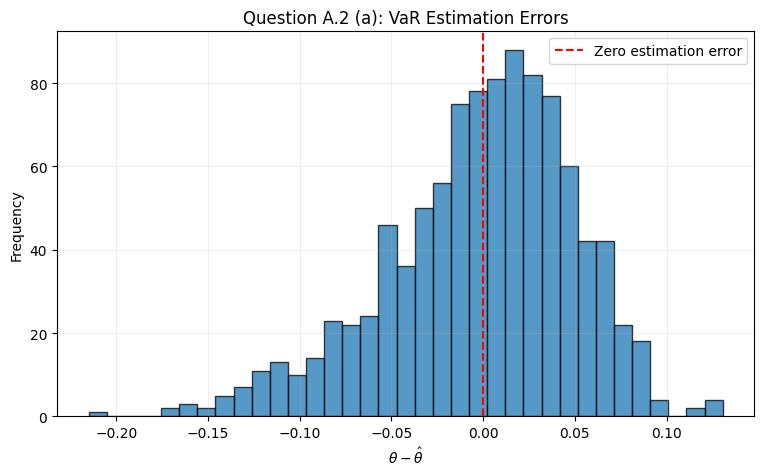

True VaR: 0.2570581835636321
Mean estimation VaR 0.2586460378459783
Mean estimation error: -0.0015878542823461828


In [ ]:
#A2a
# constants 
nu = 5
mu = 1
sigma = 0.01
n = 100
N = 1000
V0 = 10 
a = 0.025

np.random.seed(37)

theta_true = -V0 * (t.ppf(a, df=nu, loc=mu, scale=sigma) - 1)


error_list = []
estimate_list = []
for i in range(N):

    R = t.rvs(df=nu, loc=mu, scale=sigma, size=n)

    X = V0 * (R - 1)
    L = -X
    theta_est = np.quantile(L, p, method = "inverted_cdf")
    

    error_list.append(float(theta_true - theta_est))

    estimate_list.append(theta_est)



plt.figure(figsize=(9, 5))
plt.hist(error_list, bins=35, edgecolor="black", alpha=0.75)
plt.axvline(0, color="red", linestyle="--", label="Zero estimation error")
plt.xlabel(r"$\theta - \hat{\theta}$")
plt.ylabel("Frequency")
plt.title("Question A.2 (a): VaR Estimation Errors")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("True VaR:", theta_true)
print("Mean estimation VaR", np.mean(estimate_list))
print("Mean estimation error:", np.mean(error_list))



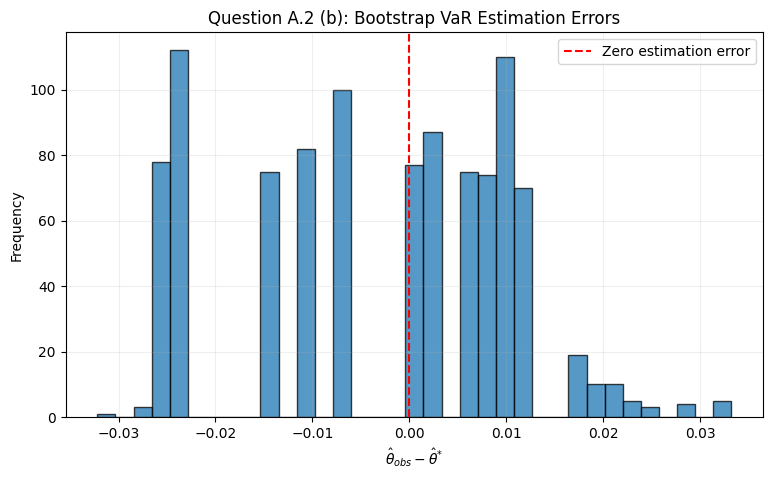

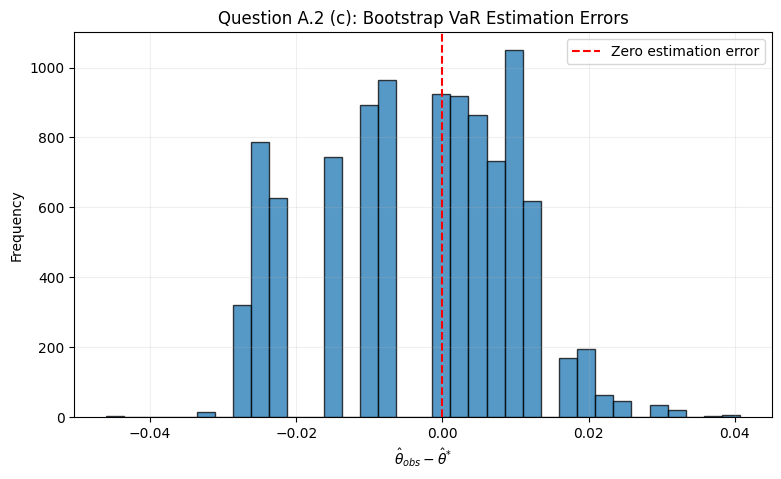

True


In [ ]:
#A2b
np.random.seed(37)
n = 700
p = 0.975

R_samples = t.rvs(df=nu, loc=mu, scale=sigma, size=n)
theta_true = -V0 * (t.ppf(a, df=nu, loc=mu, scale=sigma) - 1)

def Bootstrap(N):


    X_obs = 10 * (R_samples - 1)
    L_obs = -X_obs

    theta_obs = np.quantile(L_obs, p, method="inverted_cdf")

    boot_samples = np.random.choice(R_samples, size = (N, n), replace = True)

    X_star = 10 * (boot_samples - 1)
    L_star = -X_star

    theta_star = np.quantile(L_star, p, axis=1, method = "inverted_cdf")
    return theta_obs, theta_star

theta_obs_b, theta_star_b = Bootstrap(1000)
boot_error_b = theta_obs_b - theta_star_b

theta_obs_c, theta_star_c = Bootstrap(10000)
boot_error_c = theta_obs_c - theta_star_c


plt.figure(figsize=(9, 5))
plt.hist(boot_error_b, bins=35, edgecolor="black", alpha=0.75)
plt.axvline(0, color="red", linestyle="--", label="Zero estimation error")
plt.xlabel(r"$\hat{\theta}_{obs} - \hat{\theta}^{*}$")
plt.ylabel("Frequency")
plt.title("Question A.2 (b): Bootstrap VaR Estimation Errors")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


plt.figure(figsize=(9, 5))
plt.hist(boot_error_c, bins=35, edgecolor="black", alpha=0.75)
plt.axvline(0, color="red", linestyle="--", label="Zero estimation error")
plt.xlabel(r"$\hat{\theta}_{obs} - \hat{\theta}^{*}$")
plt.ylabel("Frequency")
plt.title("Question A.2 (c): Bootstrap VaR Estimation Errors")
plt.legend()
plt.grid(alpha=0.2)
plt.show()





Exact method: 90/100
Bootstrap method: 80/100


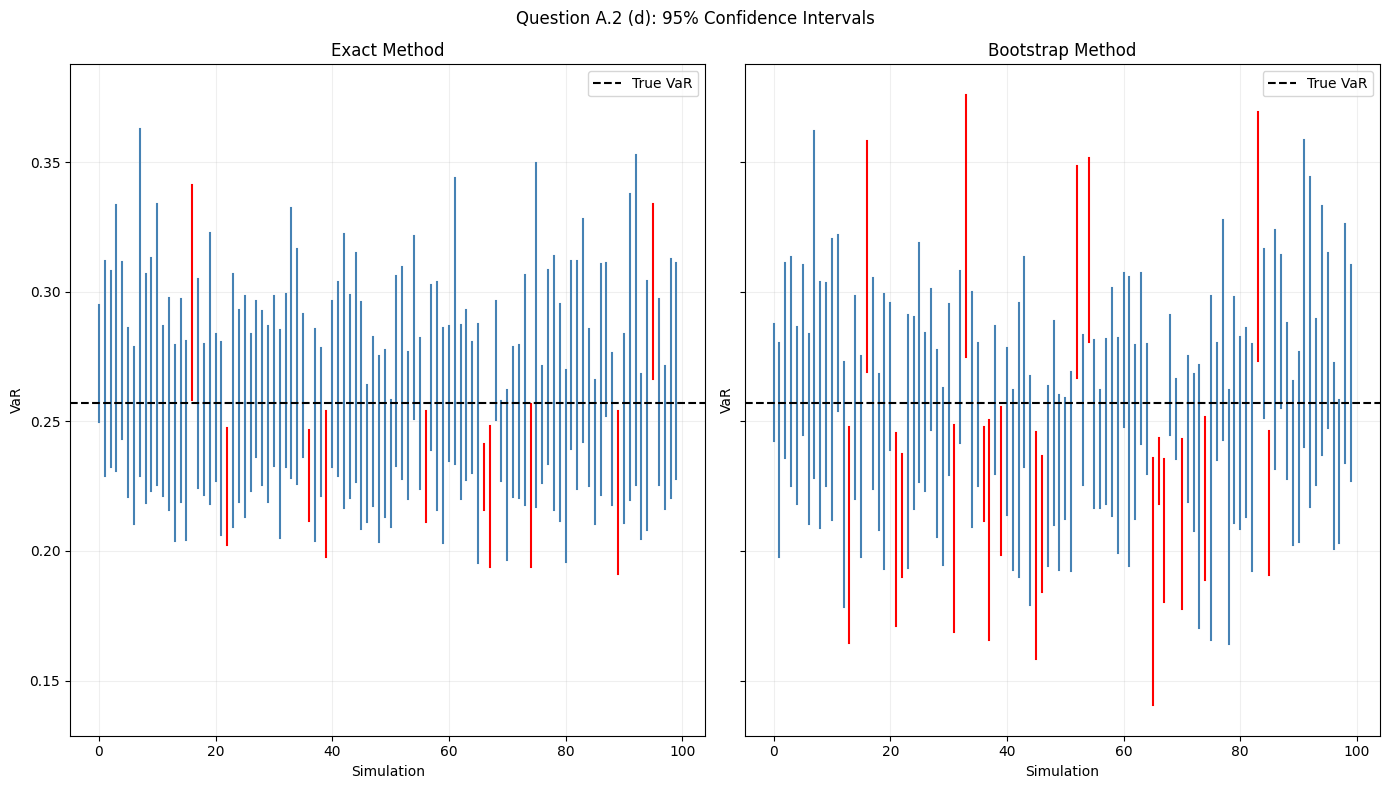

In [ ]:
np.random.seed(37)

n = 700
N = 1000
k = 100
p = 0.975
q = 0.95

lower = int(N * (1-q)/2)
upper = int(N * (1+q)/2)

theta_true = -V0 * (t.ppf(1-p, df=nu, loc=mu, scale=sigma) - 1)

exact_lower = []
exact_upper = []

boot_lower = []
boot_upper = []


j1 = n - int(binom.ppf((1+q)/2, n, 1-p))
j2 = n - int(binom.ppf((1-q)/2, n, 1-p))

for i in range(k):
    R = t.rvs(df=nu, loc=mu, scale=sigma, size=n)
    X = 10 * (R - 1)
    L = -X
    L = np.sort(L)

    exact_lower.append(L[j1-1])
    exact_upper.append(L[j2-1]) 

    theta_obs_L = np.quantile(L, p, method = "inverted_cdf")

    L_boot = np.random.choice(L, size = (N, n), replace = True)

    theta_star_L = np.quantile(L_boot, p, axis=1, method = "inverted_cdf")
    error_L = theta_obs_L - theta_star_L

    error_sorted_L = np.sort(error_L)

    boot_lower.append(theta_obs_L + error_sorted_L[lower-1])
    boot_upper.append(theta_obs_L + error_sorted_L[upper-1])



exact_coverage = np.sum(
    (np.array(exact_lower) <= theta_true) &
    (theta_true <= np.array(exact_upper))
)

boot_coverage = np.sum(
    (np.array(boot_lower) <= theta_true) &
    (theta_true <= np.array(boot_upper))
)  

print(f"Exact method: {exact_coverage}/100")
print(f"Bootstrap method: {boot_coverage}/100")


fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharex=True, sharey=True)

for ax, ci_lower, ci_upper, title in zip(
    axes,
    [exact_lower, boot_lower],
    [exact_upper, boot_upper],
    ["Exact Method", "Bootstrap Method"]
):
    for i in range(k):
        color = "steelblue" if ci_lower[i] <= theta_true <= ci_upper[i] else "red"

        ax.plot([i, i], [ci_lower[i], ci_upper[i]],
                color=color, linewidth=1.5)

    ax.axhline(theta_true, color="black",
               linestyle="--", label="True VaR")

    ax.set_title(title)
    ax.set_xlabel("Simulation")
    ax.set_ylabel("VaR")
    ax.grid(alpha=0.2)
    ax.legend()

plt.suptitle("Question A.2 (d): 95% Confidence Intervals")
plt.tight_layout()
plt.show()



